# 04 · Data Augmentation: Teaching the Model What the Field Looks Like
**Course Module 4: Improving the data (data augmentation)**

**Strategy:** notebook 01 found *why* lab models fail in the field: backgrounds leak the label, and field photos differ in clutter, lighting and color.
Augmentation is the tool that attacks exactly this: we transform training images at random so the model cannot rely on things that change in the field.

We run a **controlled ablation**: same model (MobileNetV3, fine-tuned), same recipe, same epochs. **Only the augmentation changes**, one step at a time.
Published work has no controlled numbers for these augmentations on PlantVillage → PlantDoc, so this table is a genuine contribution.

**How we choose the winner, honestly:** every model is scored on **PlantDoc validation** (photos from PlantDoc's *train* folder that no lab-track model ever trained on) and on **PlantDoc test**.
We pick the winner on *validation* and only *report* test. Choosing on the test set would make the final number optimistic.

| Recipe | What it adds | Field problem it targets |
|---|---|---|
| `none` | resize + center crop | (reference) |
| `basic` | random crop/zoom + flips | leaf position, scale, orientation |
| `color` | + brightness/contrast/saturation jitter, blur, rotation | sunlight, shadows, phone camera blur |
| `randaug` | + RandAugment (2 random strong ops per image) | general robustness |
| `bg_synthetic` | + **background replacement** with random colors and textures | the background shortcut, with no field data used |
| `bg_field` | + background replacement with crops of *unlabeled* PlantDoc train photos | the background shortcut, with realistic clutter |

In [1]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from lab_to_field.config import N_CLASSES, FIGURES_DIR, IMAGENET_MEAN, IMAGENET_STD
from lab_to_field.data import BackgroundReplacer, build_transforms
from lab_to_field.train import TrainConfig, load_results
from lab_to_field.experiment import run, splits
plt.rcParams["figure.dpi"] = 110
S = splits()

## 1. See each augmentation
Augmentation happens **on the fly**: every epoch the model sees a *new random version* of each photo. The dataset on disk never changes.

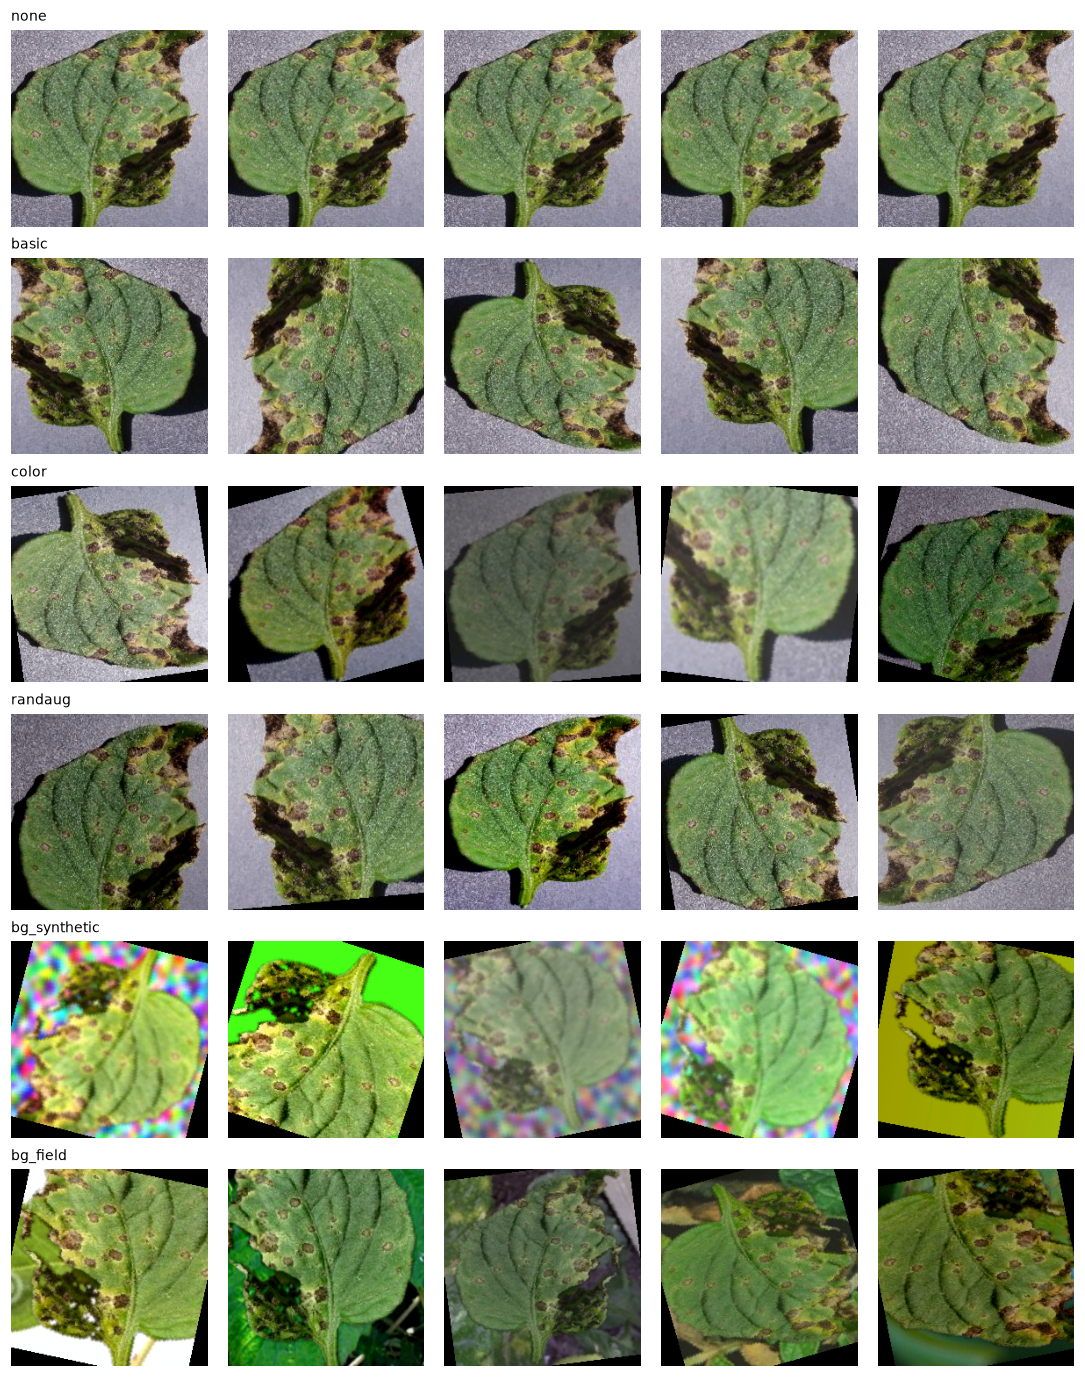

In [2]:
def denorm(t):
    return (t.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1)

path = S["lab_train"].sample(1, random_state=3).path.iloc[0]
bg_syn = BackgroundReplacer("synthetic", p=1.0)
bg_fld = BackgroundReplacer("field", p=1.0, field_paths=S["field_train"].path.tolist())
recipes = ["none", "basic", "color", "randaug", "bg_synthetic", "bg_field"]
fig, axes = plt.subplots(len(recipes), 5, figsize=(10, 2.1 * len(recipes)))
for r, kind in enumerate(recipes):
    tf = build_transforms(kind, 224, train=True)
    for c in range(5):
        img = bg_syn(path) if kind == "bg_synthetic" else bg_fld(path) if kind == "bg_field" else Image.open(path).convert("RGB")
        axes[r, c].imshow(denorm(tf(img))); axes[r, c].axis("off")
    axes[r, 0].set_title(kind, loc="left", fontsize=9)
plt.tight_layout(); fig.savefig(FIGURES_DIR / "04_augmentations.png", bbox_inches="tight")

## 2. How background replacement works (our key augmentation)
PlantVillage also ships a **segmented** copy of each photo: the leaf on pure black.
1. Load the segmented leaf and build a **mask**: pixel is leaf if it is brighter than near-black.
2. Shrink the mask by one pixel (removes a dark halo) and soften the edge (blur), so the paste looks natural.
3. Choose a new background (random color, gradient or texture, or a crop of a real field photo).
4. Paste the leaf onto the background through the mask; then the normal crop/color augmentations follow.

The leaf (with its disease) stays the same, but the background is new every time, so **the background can no longer predict the label**.
The model is forced to look at the lesions.

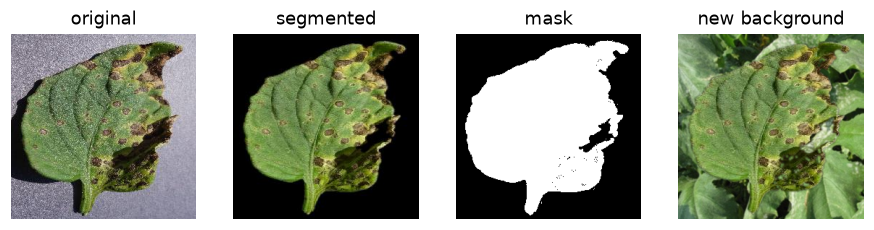

In [3]:
seg = Image.open(path.replace("/color/", "/segmented/").rsplit(".", 1)[0] + "_final_masked.jpg")
fig, ax = plt.subplots(1, 4, figsize=(10, 2.6))
mask = (np.asarray(seg.convert("RGB")).max(2) > 20)
for a, im, t in zip(ax, [Image.open(path), seg, mask, bg_fld(path)], ["original", "segmented", "mask", "new background"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
fig.savefig(FIGURES_DIR / "04_bg_replacement.png", bbox_inches="tight")

## 3. The ablation
Each run: MobileNetV3-Large, fine-tuned, 6 epochs, AdamW lr 1e-3, lab track (best epoch chosen on *lab* validation).

In [4]:
for kind in ["none", "basic", "color", "randaug", "bg_synthetic", "bg_field"]:
    name = f"04_aug_{kind}"
    if kind == "basic" and "03_mnv3_finetune" in load_results():
        continue  # identical to notebook 03's fine-tuning run, reuse it
    run(TrainConfig(name=name, model="mobilenetv3_large_100", lr=1e-3, epochs=6, augment=kind), track="lab")

[04_aug_none] loaded saved result (delete 04_aug_none.json or pass force=True to retrain): lab acc 0.991 | field val 0.154 | field test 0.258
[04_aug_color] loaded saved result (delete 04_aug_color.json or pass force=True to retrain): lab acc 0.989 | field val 0.200 | field test 0.326
[04_aug_randaug] loaded saved result (delete 04_aug_randaug.json or pass force=True to retrain): lab acc 0.990 | field val 0.197 | field test 0.284
[04_aug_bg_synthetic] loaded saved result (delete 04_aug_bg_synthetic.json or pass force=True to retrain): lab acc 0.979 | field val 0.277 | field test 0.390
[04_aug_bg_field] loaded saved result (delete 04_aug_bg_field.json or pass force=True to retrain): lab acc 0.983 | field val 0.289 | field test 0.314


In [5]:
R = load_results()
order = ["none", "basic", "color", "randaug", "bg_synthetic", "bg_field"]
rows = []
for kind in order:
    key = "03_mnv3_finetune" if kind == "basic" and "04_aug_basic" not in R else f"04_aug_{kind}"
    r = R[key]
    rows.append({"augmentation": kind, "lab acc": r["lab_test"]["accuracy"], "field val acc": r["field_val"]["accuracy"],
                 "field acc": r["field_test"]["accuracy"],
                 "field 95% CI": "{:.1%}–{:.1%}".format(*r["field_test"]["accuracy_ci95"]),
                 "field macro-F1": r["field_test"]["macro_f1"], "field ECE": r["field_test"]["ece"]})
abl = pd.DataFrame(rows)
abl["field gain vs none (pts)"] = (abl["field acc"] - abl["field acc"].iloc[0]) * 100
print("winner chosen on field VALIDATION:", abl.loc[abl["field val acc"].idxmax(), "augmentation"])
abl.round(3)

winner chosen on field VALIDATION: bg_field


,augmentation,lab acc,field val acc,field acc,field 95% CI,field macro-F1,field ECE,field gain vs none (pts)
0,none,0.991,0.154,0.258,20.8%–31.8%,0.256,0.569,0.000
1,basic,0.989,0.180,0.301,24.2%–36.4%,0.264,0.515,4.237
2,color,0.989,0.200,0.326,26.3%–38.1%,0.287,0.489,6.780
3,randaug,0.990,0.197,0.284,22.9%–33.9%,0.249,0.538,2.542
4,bg_synthetic,0.979,0.277,0.390,33.1%–45.3%,0.357,0.429,13.136
5,bg_field,0.983,0.289,0.314,25.4%–37.7%,0.287,0.444,5.508


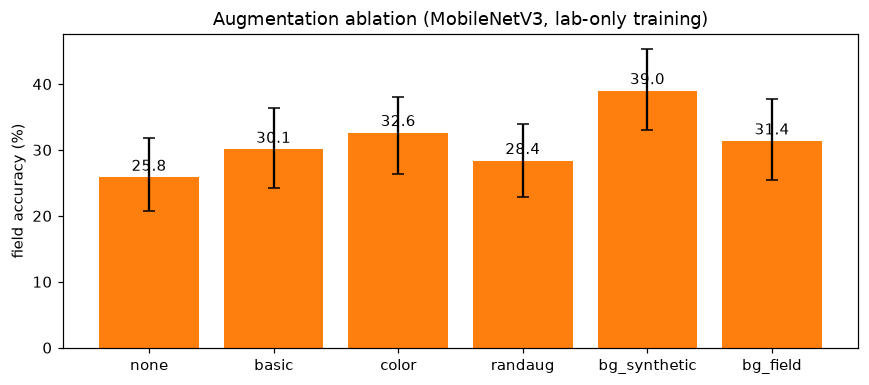

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
lo = [float(s.split("–")[0].strip("%")) for s in abl["field 95% CI"]]
hi = [float(s.split("–")[1].strip("%")) for s in abl["field 95% CI"]]
f = abl["field acc"] * 100
ax.bar(abl.augmentation, f, color="tab:orange", yerr=[f - lo, np.array(hi) - f], capsize=4)
ax.set_ylabel("field accuracy (%)"); ax.set_title("Augmentation ablation (MobileNetV3, lab-only training)")
for i, v in enumerate(f): ax.text(i, v + 1, f"{v:.1f}", ha="center")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "04_ablation.png", bbox_inches="tight")

## 4. How to read the results
- **Lab accuracy barely moves** between recipes: augmentation is not about the lab score.
- **Field accuracy is what changes.** Compare each row with the one above it to see what *that one* augmentation added.
- **Error bars:** PlantDoc test has ~230 photos, so differences of 2–3 points can be noise. Only claim a gain if the confidence intervals clearly separate, or if it repeats with more seeds.
- **`bg_synthetic` vs `bg_field`:** both remove the background shortcut. `bg_field` also shows the model realistic clutter, but uses (unlabeled) field photos, so it is no longer "lab only". We report it separately for honesty.

**Decision:** the recipe with the best *field validation* accuracy becomes the default for notebook 05 and the final model.

### Our results
| Augmentation | Field **val** acc (used to choose) | Field **test** acc (only reported) |
|---|---|---|
| none | 15.4% | 25.8% |
| basic | 18.0% | 30.1% |
| color | 20.0% | 32.6% |
| randaug | 19.7% | 28.4% |
| **bg_synthetic** | 27.7% | **39.0%** |
| **bg_field** | **28.9%** | 31.4% |

1. **Background replacement is the clear winner** on both validation and test: about **+12 to +13 points** over no augmentation, and well above every other recipe. Removing the background shortcut found in notebook 01 is what helps most.
2. **Generic strong augmentation (RandAugment) does not help.** Augmentation works when it targets the actual difference between training and deployment data.
3. **Validation and test disagree on the winner** (bg_field on val by 1.2 points, bg_synthetic on test by 7.6 points). We still follow validation, because choosing on the test set is cheating. The disagreement itself is a finding: with a few hundred field photos, differences of a few points are noise.
4. A likely reason bg_field is not better on test: real field crops often contain *other* diseased leaves, which can confuse the label.

**Limitation we noticed:** PlantVillage's own segmentation sometimes removes dark, diseased leaf edges (visible as holes in the `bg_*` rows above), so part of a lesion can be replaced by background. A better leaf mask (e.g. a segmentation model, Module 6) is a natural next step.

## Review questions
1. Why is augmentation applied on the fly instead of saving augmented copies to disk? (Also: why do pre-augmented Kaggle copies of PlantVillage leak test data?)
2. Which augmentation targets which difference between lab and field photos?
3. Explain background replacement step by step. Why does it remove the shortcut found in notebook 01?
4. Why do we change only one thing per run?
5. Why do we never apply augmentation to the test set?
6. Is a 2-point gain on 230 test images meaningful? How do you check?